# Magnetized Metalic Objects - One-Dimensional Galerkin

## Import Packages 

In [2]:
using StaticArrays   # provides statically typed arrays 
using SparseArrays   # provides sparse arrays 
using LinearAlgebra
using Printf
using Plots

## Section 1: Introduction 

Provides 1D Galerkin FEM code wioth linear elements. More later. 

<b>Exercises</b>
1. validate the code showing quadratic reduction of error in max-norm given analytical solution;
2. extend to 2D / 3D;
3. extend with an integral term;

## Section 2: Entire Code Base 

In [4]:
"""
    struct Elem1DLin  

Holds information for a single linear line finite element. 
"""
struct Elem1DLin
  inode::SVector{2,Int64} # element global node tag 
  len::Float64            # element length  
end; 

"""
    struct Mesh 

Holds information for the entire mesh as an array of linear line elements. 
"""
struct Mesh 
  nodes::Array{Float64,1}      # 1D array of nodes 
  elements::Array{Elem1DLin,1} # 1D array of Elem1DLin  
end; 

function genVec(mesh, sourcefct)
    
    Np1 = length(mesh.elements)+1
    nodes = mesh.nodes 
    
    f = zeros(Np1)

    for (k,element) in enumerate(mesh.elements) 
        f[element.inode] += element.len*sourcefct.(nodes[element.inode])
    end 

    f ./= 2
   
    return f 
    
end;

function genMatDense(mesh)
    
    Np1 = length(mesh.elements)+1
    nodes = mesh.nodes 
    
    A = zeros(Np1,Np1)

    for (k,element) in enumerate(mesh.elements) 
        inode = element.inode
        A[inode,inode] += 1/element.len*[1. -1.;-1. 1.]
    end 
   
    return A 
    
end; 

function genMat(mesh)
    
    nelems      = length(mesh.elements)
    dofPerElem  = length(mesh.elements[1].inode)
    dofPerElem2 = dofPerElem^2 
    
    Avals = zeros(Float64,dofPerElem2*nelems)
    I = zeros(Int64,length(Avals))
    J = zeros(Int64,length(Avals))

    irng = SVector{dofPerElem2}(1:dofPerElem2)
    
    for (k,element) in enumerate(mesh.elements) 
        Ielem = SVector{dofPerElem2}(element.inode[i] for j=1:dofPerElem, i=1:dofPerElem) 
        Jelem = SVector{dofPerElem2}(element.inode[i] for i=1:dofPerElem, j=1:dofPerElem)
        Aelem = 1/(element.len)*SVector{dofPerElem2}(1.,-1., -1., 1.) 
        I[irng] .= Ielem  
        J[irng] .= Jelem  
        Avals[irng] .= Aelem    
        irng = irng.+dofPerElem2    
    end 
   
    A = sparse(I,J,Avals)
    
    return A 
    
end; 

function genMass(mesh)
    nelems      = length(mesh.elements)
    dofPerElem  = length(mesh.elements[1].inode)
    dofPerElem2 = dofPerElem^2 
    
    Mvals = zeros(Float64,dofPerElem2*nelems)
    I = zeros(Int64,length(Mvals))
    J = zeros(Int64,length(Mvals))

    irng = SVector{dofPerElem2}(1:dofPerElem2)
    
    for (k,element) in enumerate(mesh.elements) 
        Ielem = SVector{dofPerElem2}(element.inode[i] for j=1:dofPerElem, i=1:dofPerElem) 
        Jelem = SVector{dofPerElem2}(element.inode[i] for i=1:dofPerElem, j=1:dofPerElem)
        Melem = (element.len)/6*SVector{dofPerElem2}(2.,1., 1., 2.) 
        I[irng] .= Ielem  
        J[irng] .= Jelem  
        Mvals[irng] .= Melem    
        irng = irng.+dofPerElem2    
    end 
   
    M = sparse(I,J,Mvals)
    
    return M 
    
end; 

## Section 3: Sample Usage 

### Mesh Generation and Elementary Verifications  

In [7]:
# set uniform mesh with N cells and h = 1/N meshwidth  
N = 4; h = 1/N; Np1 = N+1; 

# set the pionts in the mesh 
nodes = Vector(0:h:1); 

# set the mesh 
mesh = Mesh(nodes, [Elem1DLin([k,k+1], nodes[k+1]-nodes[k]) for k=1:N]); 

In [8]:
sum([elem.len for elem in mesh.elements])

sum(map(x -> x.len, mesh.elements))
    
mapreduce(x -> x.len, +, mesh.elements)

1.0

In [9]:
# extract nodes and elements from mesh 
(; nodes, elements) = mesh 
display(nodes)
display(elements)

5-element Vector{Float64}:
 0.0
 0.25
 0.5
 0.75
 1.0

4-element Vector{Elem1DLin}:
 Elem1DLin([1, 2], 0.25)
 Elem1DLin([2, 3], 0.25)
 Elem1DLin([3, 4], 0.25)
 Elem1DLin([4, 5], 0.25)

### Generate Load Vector 

In [11]:
sourcefct(x) = x^2 
sourcefct.(nodes[mesh.elements[2].inode])

2-element SVector{2, Float64} with indices SOneTo(2):
 0.0625
 0.25

In [12]:
f = zeros(Np1)

for (k,element) in enumerate(mesh.elements) 
    f[element.inode] += element.len*sourcefct.(nodes[element.inode])
end 

display(f)

5-element Vector{Float64}:
 0.0
 0.03125
 0.125
 0.28125
 0.25

In [13]:
f = genVec(mesh, sourcefct)

5-element Vector{Float64}:
 0.0
 0.015625
 0.0625
 0.140625
 0.125

In [14]:
#@code_warntype genVec(mesh, x->x^2)

### Generate Stiffness Matrix 

In [16]:
A = zeros(Np1,Np1)

for (k,element) in enumerate(mesh.elements) 
    A[element.inode,element.inode] += (1.0/element.len)*[1. -1.;-1. 1.]
end 

display(A)

5×5 Matrix{Float64}:
  4.0  -4.0   0.0   0.0   0.0
 -4.0   8.0  -4.0   0.0   0.0
  0.0  -4.0   8.0  -4.0   0.0
  0.0   0.0  -4.0   8.0  -4.0
  0.0   0.0   0.0  -4.0   4.0

In [17]:
N = 4
A = genMatDense(mesh)

5×5 Matrix{Float64}:
  4.0  -4.0   0.0   0.0   0.0
 -4.0   8.0  -4.0   0.0   0.0
  0.0  -4.0   8.0  -4.0   0.0
  0.0   0.0  -4.0   8.0  -4.0
  0.0   0.0   0.0  -4.0   4.0

In [18]:
A = genMat(mesh)

5×5 SparseMatrixCSC{Float64, Int64} with 13 stored entries:
  4.0  -4.0    ⋅     ⋅     ⋅ 
 -4.0   8.0  -4.0    ⋅     ⋅ 
   ⋅   -4.0   8.0  -4.0    ⋅ 
   ⋅     ⋅   -4.0   8.0  -4.0
   ⋅     ⋅     ⋅   -4.0   4.0

## Poisson Solver

In [20]:
# Generate a uniform mesh on [0,1].
function makeMesh(N)
    nodes = collect(range(0.0, 1.0; length=N+1))

    elements = [
        Elem1DLin([k, k+1], nodes[k+1] - nodes[k])
        for k in 1:N
    ]

    return Mesh(nodes, elements)
end

function solveFEM(mesh, sourcefct, genB;
                  uleft=0.0, uright=0.0)
    # Generate system matrix
    B = genB(mesh)

    # Generate load vector
    b = genVec(mesh, sourcefct)

    # Apply Dirichlet boundary conditions
    free = 2:length(mesh.nodes)-1
    fixed = [1, length(mesh.nodes)]

    u = zeros(length(mesh.nodes))
    u[1] = uleft
    u[end] = uright

    # Solve reduced system
    u[free] = B[free, free] \ (b[free] - B[free, fixed] * u[fixed])

    return u
end

# Maximum error at the mesh nodes.
function maxError(mesh, u, exact)
    return maximum(abs.(u .- exact.(mesh.nodes)))
end

maxError (generic function with 1 method)

In [21]:
# Exact solution and source term.
uexact(x) = sin(π*x)
sourcefct(x) = π^2*sin(π*x)
#uexact(x) = (x-x^2)/2
#sourcefct(x) = 1
#uexact(x) = (x-x^3)/6
#sourcefct(x) = x
#uexact(x) = (x-x^4)/12
#sourcefct(x) = x^2
#uexact(x) = 1 + (ℯ - 1) * x - exp(x)
#sourcefct(x) = exp(x)
#uexact(x) = x * (1 - x)
#sourcefct(x) = 2.0
uexact(x) = -1/6*x^4 + 2/3*x^3+x^2-7/12*x 
sourcefct(x) = -2 - 4*x +2*x^2

N_values = (4, 8, 16, 32, 64)

genPoisson(mesh) = genMat(mesh)

function compute(N_values,mesh,f,generator; uleft=0.0,uright=0.0)
    h_values = Float64[]
    errors = Float64[]
    rates = Float64[]
    previous_error = NaN
    u = NaN
    mesh = nothing
    println(" N       h          max error       rate")
    for N in N_values
        mesh = makeMesh(N)
        genPoisson(mesh) = genMat(mesh)
        u = solveFEM(mesh, f,generator, uleft=uleft,uright=uright)
    
        h = 1.0 / N
        err = maxError(mesh, u, uexact)
    
        rate = isnan(previous_error) ? NaN :
               log(previous_error / err) / log(2)
    
        push!(h_values, h)
        push!(errors, err)
        push!(rates, rate)
    
        @printf("%3d   %.6f   %.6e   %5.2f\n",
                N, h, err, rate)
    
        previous_error = err
    end
    return u, h_values, errors, rates
end 

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genPoisson(mesh),uright=11/12)

 N       h          max error       rate
  4   0.250000   2.604167e-03     NaN
  8   0.125000   6.510417e-04    2.00
 16   0.062500   1.627604e-04    2.00
 32   0.031250   4.069010e-05    2.00
 64   0.015625   1.017253e-05    2.00


([0.0, -0.00886853535970041, -0.01723364988962787, -0.025080442428588538, -0.03239425023396767, -0.03916064898172961, -0.04536545276641781, -0.050994714101154845, -0.05603472391764236, -0.06047201156616114  …  0.5694286028544137, 0.6041215260823594, 0.6397833824157737, 0.6764159599940001, 0.7140208085378025, 0.7525992393493662, 0.7921523253122974, 0.8326809008916226, 0.8741855621337893, 0.9166666666666666], [0.25, 0.125, 0.0625, 0.03125, 0.015625], [0.0026041666666666713, 0.0006510416666665048, 0.0001627604166665915, 4.0690104167281915e-5, 1.0172526038881857e-5], [NaN, 2.0000000000003615, 2.0000000000003073, 1.9999999999775195, 2.000000000416763])

### plotCompare:
Input: calculated u array and the uexact function
Output: plot comparing the numartical solution to the analitical solution.

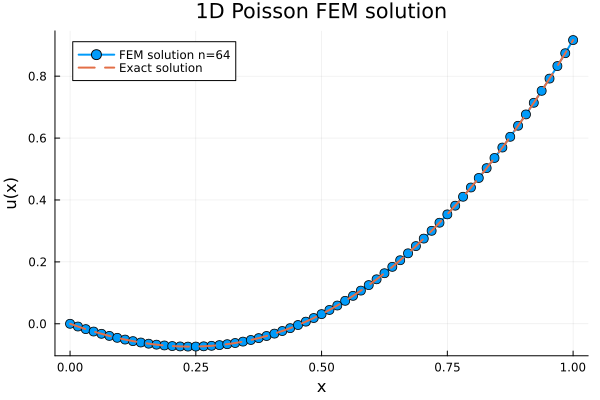

In [23]:
function plotCompare(u,uexact;title="1D Poisson FEM solution")
    x = range(0.0, 1.0; length=length(u))
    plot(x, u,
         label = "FEM solution n=64",
         marker = :circle,
         markersize = 5,
         linewidth = 2,
         xlabel = "x",
         ylabel = "u(x)",
         title = title)
    
    plot!(x, uexact.(x),
          label = "Exact solution",
          linestyle = :dash,
          linewidth = 2)
end

plotCompare(u,uexact)

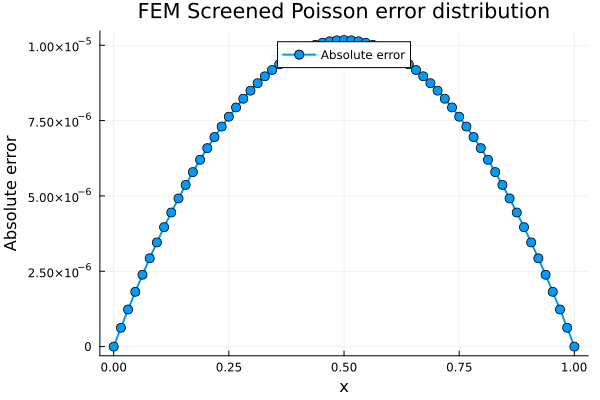

In [24]:
x = range(0.0, 1.0; length=length(u))
error = abs.(uexact.(x) .- u)

plot(x, error,
     label = "Absolute error",
     marker = :circle,
     markersize = 5,
     linewidth = 2,
     xlabel = "x",
     ylabel = "Absolute error",
     title = "FEM Screened Poisson error distribution",
     legend = :top)

#png("FEM_error_screened_Poisson")

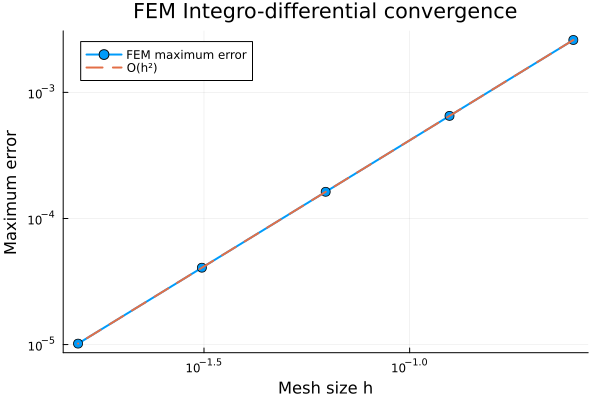

In [25]:
p = 2.0

plot(h_values, errors,
     xscale = :log10,
     yscale = :log10,
     marker = :circle,
     markersize = 5,
     linewidth = 2,
     label = "FEM maximum error",
     xlabel = "Mesh size h",
     ylabel = "Maximum error",
     title = "FEM Integro-differential convergence")

# Reference line proportional to h^2
reference = errors[1] .* (h_values ./ h_values[1]).^p

plot!(h_values, reference,
      linestyle = :dash,
      linewidth = 2,
      label = "O(h²)")

#png("FEM_convergence_integro")

## Screened Poisson FEM solver

In [27]:
genScreened(mesh; k=2.0) = genMat(mesh) + k^2*genMass(mesh)

genScreened (generic function with 1 method)

 N       h          max error       rate
  4   0.250000   6.836710e-02     NaN
  8   0.125000   1.668962e-02    2.03
 16   0.062500   4.147573e-03    2.01
 32   0.031250   1.035346e-03    2.00
 64   0.015625   2.587399e-04    2.00


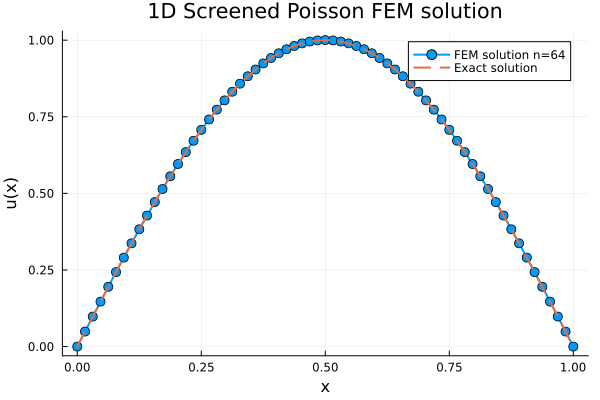

In [28]:
k = 2.0
sourcefct(x) = (k^2+π^2)*sin(π*x)
uexact(x) = sin(π*x)

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genScreened(mesh; k=2.0))
plotCompare(u,uexact,title="1D Screened Poisson FEM solution")

In [29]:
#png("1D_screened_Poisson")

## Integro-differential FEM solver

The function genIntegralMat(mesh, kernel) constructs a global integral matrix by evaluating a double integral over all pairs of elements in a one-dimensional mesh. The integration is performed numerically using a two-point Gauss–Legendre quadrature rule.

The resulting matrix (C) is assembled from element-wise contributions and has dimensions (N \times N), where (N) is the total number of mesh nodes.

The function loops over all pairs of elements, denoted by (e_1) and (e_2). This is necessary because the integral involves two spatial variables, each associated with a potentially different element.

For each element, the nodal indices and nodal coordinates are retrieved, together with the corresponding element length (h_1) or (h_2).

The derivatives of the linear shape functions are constant within each element and are given by

$$
\mathbf{dN}_1 =
\begin{bmatrix}
-1/h_1\
1/h_1
\end{bmatrix},
\qquad
\mathbf{dN}_2 =
\begin{bmatrix}
-1/h_2\
1/h_2
\end{bmatrix}.
$$

These derivatives are used to construct the element-level matrix contribution through their outer product:

$$
\mathbf{dN}_1\mathbf{dN}_2^T.
$$

In [31]:
function genIntegralMat(mesh, kernel)

    nelems = length(mesh.elements)
    nnodes = length(mesh.nodes)

    C = zeros(nnodes, nnodes)

    # Two-point Gauss quadrature
    ξq = (-1/sqrt(3), 1/sqrt(3))
    wq = (1.0, 1.0)

    for elem1 in mesh.elements

        ids1 = elem1.inode
        x1, x2 = mesh.nodes[ids1]
        h1 = elem1.len

        # Derivatives of shape functions
        dN1 = SVector(-1/h1, 1/h1)

        for elem2 in mesh.elements

            ids2 = elem2.inode
            y1, y2 = mesh.nodes[ids2]
            h2 = elem2.len

            dN2 = SVector(-1/h2, 1/h2)

            # Integrate over both elements
            for q in eachindex(ξq), r in eachindex(ξq)

                ξ = ξq[q]
                η = ξq[r]

                x = (x1 + x2)/2 + h1*ξ/2
                xp = (y1 + y2)/2 + h2*η/2

                weight = (h1/2)*(h2/2)*wq[q]*wq[r]

                C[ids1, ids2] .+=
                    weight * kernel(x, xp) * (dN1 * dN2')
            end
        end
    end

    return C
end

genIntegralMat (generic function with 1 method)

In [32]:
function kernelc(x, xp)
    return 1
end

function kernelr(x, xp)
    return abs.(x-xp)
end

genIntegro(mesh; k=2.0, kernel=kernelc) =
    k^2*genMass(mesh) + genIntegralMat(mesh, kernel)

genIntegro (generic function with 1 method)

 N       h          max error       rate
  4   0.250000   1.081942e-01     NaN
  8   0.125000   2.603406e-02    2.06
 16   0.062500   6.446194e-03    2.01
 32   0.031250   1.607672e-03    2.00
 64   0.015625   4.016759e-04    2.00


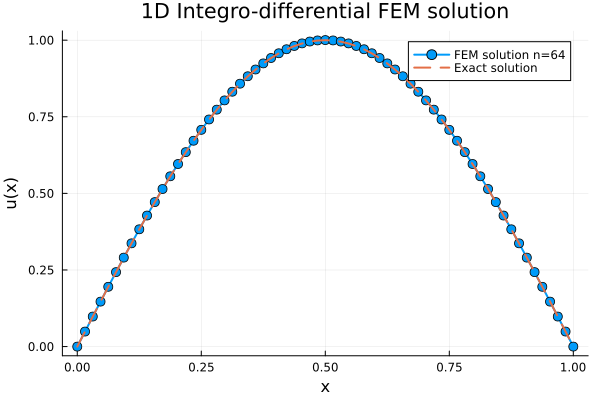

In [33]:
sourcefct(x) = k^2*sin(π*x)

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genIntegro(mesh; k=2.0, kernel=kernelc))
plotCompare(u,uexact,title="1D Integro-differential FEM solution")

In [34]:
#png("1D_Intego")

 N       h          max error       rate
  4   0.250000   1.804273e-03     NaN
  8   0.125000   4.663242e-04    1.95
 16   0.062500   1.175466e-04    1.99
 32   0.031250   2.944717e-05    2.00
 64   0.015625   7.365580e-06    2.00


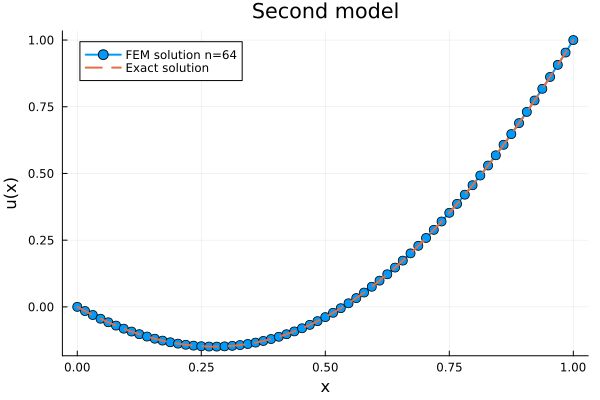

In [35]:
genAS(mesh; k=2.0, kernel=kernelc) = -genMat(mesh) - genIntegralMat(mesh, kernel)
uexact(x) = -x^2+2*x + 5/2 - 5/2*cos(sqrt.(2)*x) - 5/2*tan(sqrt.(2)/2)*sin(sqrt.(2)*x)
sourcefct(x) = 2 + 4*x - 2*x^2

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genAS(mesh; k=2.0, kernel=kernelr), uright=1.0)
plotCompare(u,uexact,title="Second model")

#png("poisson_and_integral")

 N       h          max error       rate
  4   0.250000   2.093340e-01     NaN
  8   0.125000   2.108077e-01   -0.01
 16   0.062500   2.137655e-01   -0.02
 32   0.031250   2.135791e-01    0.00
 64   0.015625   2.135631e-01    0.00


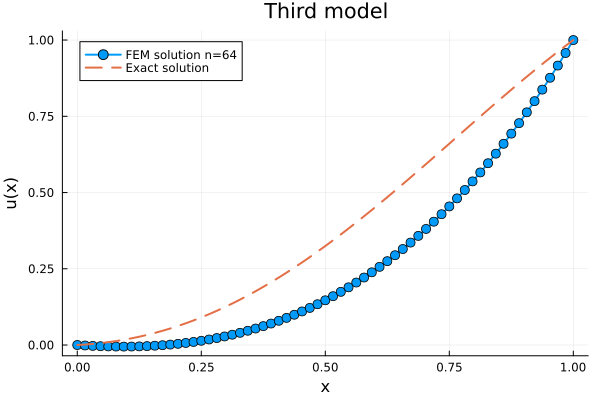

In [36]:
genAMS(mesh; k=2.0, kernel=kernelc) = -genMat(mesh) + genIntegralMat(mesh, kernel)
uexact(x) = -x^2 + x + 1 - cos(2*x) + sin(2*x)/tan(2)
sourcefct(x) = 2 + 4*x - 2*x^2

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genAMS(mesh; k=2.0, kernel=kernelr), uright=1.0)
plotCompare(u,uexact,title="Third model")

 N       h          max error       rate
  4   0.250000   3.840888e-02     NaN
  8   0.125000   4.242834e-02   -0.14
 16   0.062500   4.290640e-02   -0.02
 32   0.031250   4.330351e-02   -0.01
 64   0.015625   4.333213e-02   -0.00


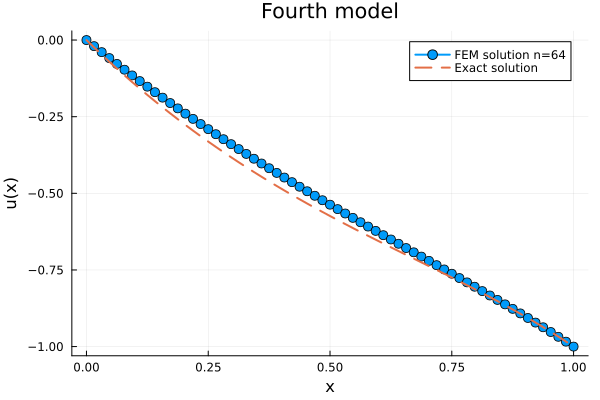

In [37]:
genAMS(mesh; k=2.0, kernel=kernelc) = -genMat(mesh) - 6*genMass(mesh) - genIntegralMat(mesh, kernel)
uexact(x) = x^2 - x - sinh(2*x)/sinh(2)
sourcefct(x) = 2 + 4*x - 2*x^2

u, h_values, errors, rates = compute(N_values,mesh,sourcefct,mesh -> genAMS(mesh; k=2.0, kernel=kernelr), uright=-1.0)
plotCompare(u,uexact,title="Fourth model")